# Diabetes Prediction with Logistic Regression

**Student:** Shaurya Sharma  |  **Student ID:** 21016956  |  **Date:** 04 November 2026

This project uses the supplied Pima Indians diabetes CSV to predict the binary Outcome label. The notebook follows the brief: inspect the data, mark invalid zero measurements, split the data, median impute, scale, train a class-balanced logistic regression model, and review the results.

## Objective and data

The target is Outcome (0 = no diabetes, 1 = diabetes). The eight predictors are Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, and Age. Zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI are treated as missing measurements. The imputer learns medians from the training rows only. This is a classroom analysis of a small historical dataset, not a medical diagnostic tool.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI","DiabetesPedigreeFunction","Age"]
ZERO_COLS = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
DATA_PATH = Path("../data/diabetes.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/diabetes.csv")
data = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {data.shape[0]} rows x {data.shape[1]} columns")
print("Outcome counts:", data["Outcome"].value_counts().sort_index().to_dict())
print("Missing cells in supplied file:", int(data.isna().sum().sum()))
print(data.head().to_string(index=False))

Dataset shape: 768 rows x 9 columns
Outcome counts: {0: 500, 1: 268}
Missing cells in supplied file: 0
 Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  BMI  DiabetesPedigreeFunction  Age  Outcome
           6      148             72             35        0 33.6                     0.627   50        1
           1       85             66             29        0 26.6                     0.351   31        0
           8      183             64              0        0 23.3                     0.672   32        1
           1       89             66             23       94 28.1                     0.167   21        0
           0      137             40             35      168 43.1                     2.288   33        1


In [2]:
zero_audit = pd.DataFrame({"feature": ZERO_COLS, "zero values": [(data[col] == 0).sum() for col in ZERO_COLS]})
print("Zero values treated as missing measurements:")
print(zero_audit.to_string(index=False))
X = data[FEATURES].copy()
X[ZERO_COLS] = X[ZERO_COLS].replace(0, np.nan)
y = data["Outcome"].astype(int)
print(f"Feature values to impute: {int(X.isna().sum().sum())}")

Zero values treated as missing measurements:
      feature  zero values
      Glucose            5
BloodPressure           35
SkinThickness          227
      Insulin          374
          BMI           11
Feature values to impute: 652


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1-score": f1_score(y_test, predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, probabilities),
}
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Test outcome counts:", y_test.value_counts().sort_index().to_dict())
print("Model: median imputation -> StandardScaler -> balanced LogisticRegression")

Training rows: 614 | Test rows: 154
Test outcome counts: {0: 100, 1: 54}
Model: median imputation -> StandardScaler -> balanced LogisticRegression


In [4]:
print("Holdout metrics:")
for metric, value in metrics.items():
    print(f"{metric:<12} {value:.3f}")
print("\nConfusion matrix (actual rows; predicted columns; labels 0, 1):")
print(matrix)
print(f"True negatives: {matrix[0,0]} | False positives: {matrix[0,1]}")
print(f"False negatives: {matrix[1,0]} | True positives: {matrix[1,1]}")

Holdout metrics:
Accuracy     0.734
Precision    0.603
Recall       0.704
F1-score     0.650
ROC-AUC      0.813

Confusion matrix (actual rows; predicted columns; labels 0, 1):
[[75 25]
 [16 38]]
True negatives: 75 | False positives: 25
False negatives: 16 | True positives: 38


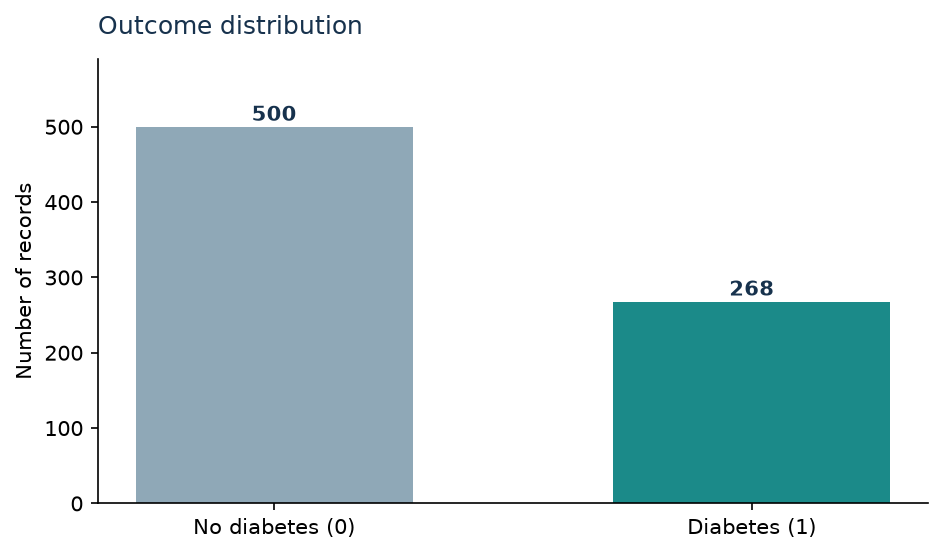

In [5]:
outcome_counts = data["Outcome"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.4, 3.8))
bars = ax.bar(["No diabetes (0)", "Diabetes (1)"], outcome_counts.values, color=["#8FA8B7", "#1B8A89"], width=0.58)
ax.set_title("Outcome distribution", loc="left", color="#17324D", pad=12)
ax.set_ylabel("Number of records")
ax.spines[["top", "right"]].set_visible(False)
ax.set_ylim(0, max(outcome_counts.values) * 1.18)
for bar, count in zip(bars, outcome_counts.values):
    ax.text(bar.get_x()+bar.get_width()/2, count+8, str(count), ha="center", color="#17324D", weight="bold")
fig.tight_layout()
plt.show()

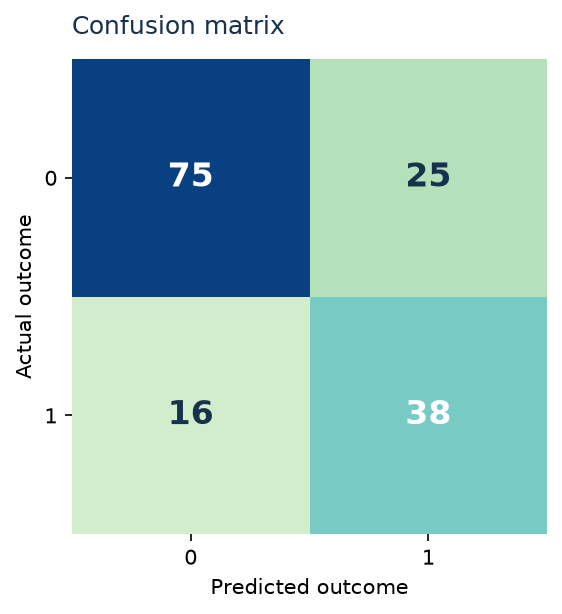

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
ax.imshow(matrix, cmap="GnBu", vmin=0)
ax.set_title("Confusion matrix", loc="left", color="#17324D", pad=12)
ax.set_xlabel("Predicted outcome")
ax.set_ylabel("Actual outcome")
ax.set_xticks([0, 1], labels=["0", "1"])
ax.set_yticks([0, 1], labels=["0", "1"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(matrix[i, j]), ha="center", va="center", color="white" if matrix[i,j] > matrix.max()/2 else "#17324D", fontsize=16, weight="bold")
for spine in ax.spines.values():
    spine.set_visible(False)
fig.tight_layout()
plt.show()

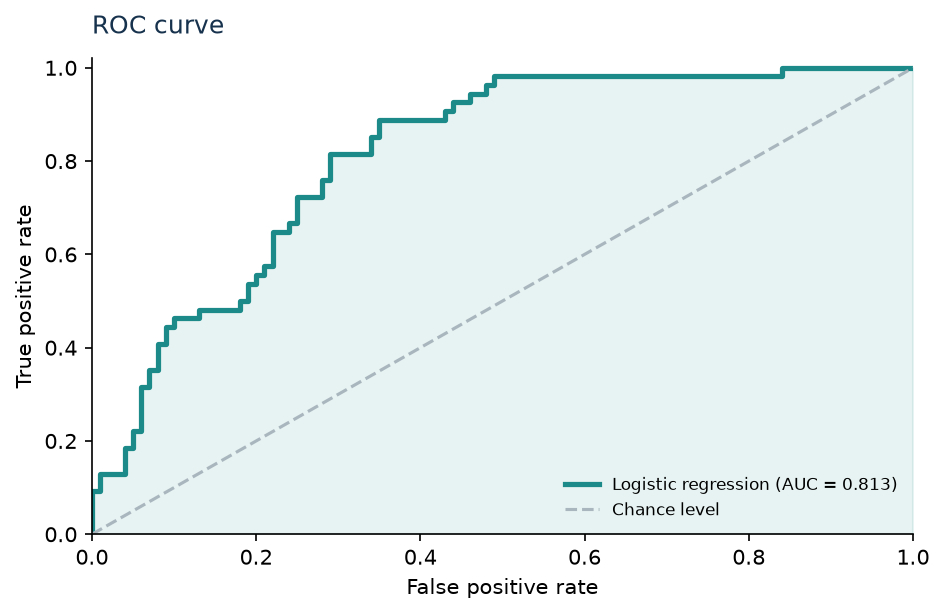

In [7]:
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(false_positive_rate, true_positive_rate, color="#1B8A89", linewidth=2.5, label=f"Logistic regression (AUC = {metrics['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#A9B6BE", label="Chance level")
ax.fill_between(false_positive_rate, true_positive_rate, alpha=0.10, color="#1B8A89")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False positive rate", ylabel="True positive rate")
ax.set_title("ROC curve", loc="left", color="#17324D", pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

Standardized coefficients (positive values increase the model score):
                 feature standardized_coefficient
                 Glucose                    1.183
                     BMI                    0.710
             Pregnancies                    0.373
DiabetesPedigreeFunction                    0.288
                     Age                    0.186
           SkinThickness                    0.014
           BloodPressure                   -0.015
                 Insulin                   -0.045


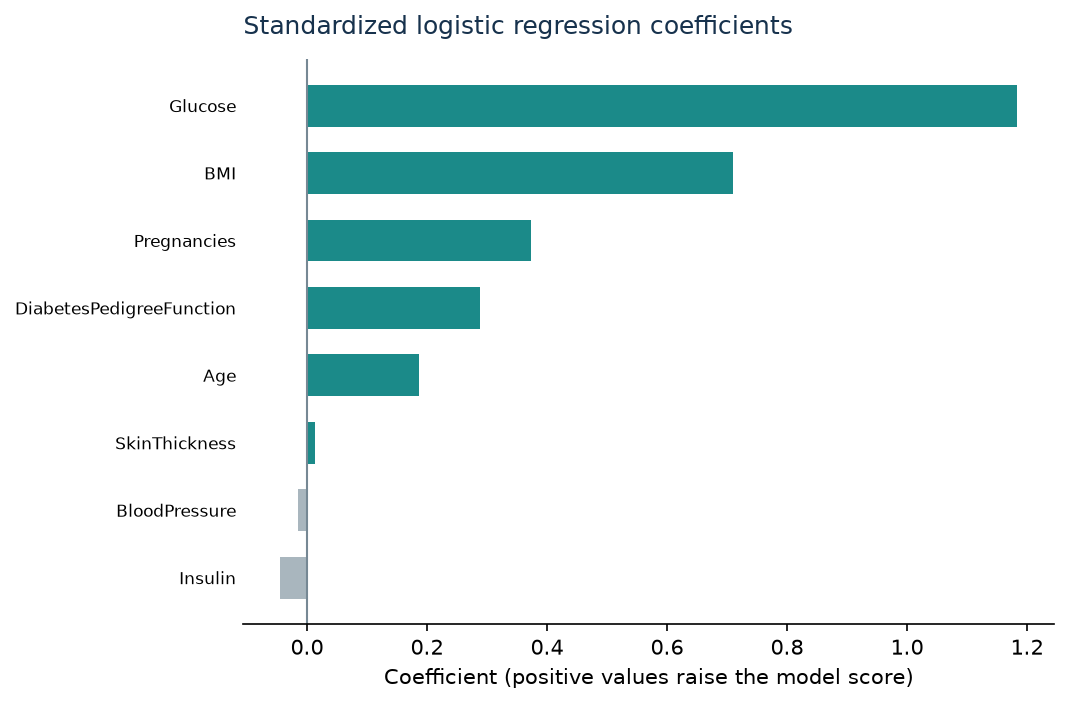

In [8]:
coefficients = pd.DataFrame({"feature": FEATURES, "standardized_coefficient": model.named_steps["classifier"].coef_[0]})
coefficients = coefficients.sort_values("standardized_coefficient", ascending=False)
print("Standardized coefficients (positive values increase the model score):")
print(coefficients.to_string(index=False, formatters={"standardized_coefficient": "{:.3f}".format}))
ordered = coefficients.sort_values("standardized_coefficient")
fig, ax = plt.subplots(figsize=(7.2, 4.8))
bar_colors = ["#1B8A89" if value >= 0 else "#A9B6BE" for value in ordered["standardized_coefficient"]]
ax.barh(ordered["feature"], ordered["standardized_coefficient"], color=bar_colors, height=0.62)
ax.axvline(0, color="#768894", linewidth=1)
ax.set_title("Standardized logistic regression coefficients", loc="left", color="#17324D", pad=12)
ax.set_xlabel("Coefficient (positive values raise the model score)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=8)
fig.tight_layout()
plt.show()

## Conclusion

On this fixed holdout split, the model correctly identified 38 of the 54 positive cases (recall 0.704) and reached a ROC-AUC of 0.813. Glucose and BMI had the largest positive standardized coefficients, so higher values in those features increased the model score in this fitted model. Recall is useful to review because false negatives are positive cases the model misses; this split had 16. The result is for learning classification methods only. The dataset is small and represents a specific population, so this model should not be used to diagnose anyone.